# Extended analysis

Three questions that go beyond the dissertation, using the corrected data and the shared code in `tfl_analysis.py`:

1. **Does network centrality predict how busy a station is?** Centrality only describes the map; ridership is what TfL actually runs.
2. **How much did the Elizabeth line increase traffic at its new central stations?** Measured with a difference-in-differences design against comparable central-London stations, using TfL counts up to 2025.
3. **How resilient is the network to station closures, and did the Elizabeth line change that?**

All outputs are written to `results/`.

In [1]:
import itertools

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr

import tfl_analysis as T

T.RESULTS.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', None)
rng = np.random.default_rng(2024)  # fixed seed: results are reproducible

## 0. Data

* **Networks:** 2014 (multiplex dataset) and 2024 without trams, built with the same rules as the main notebooks.
  The 2024 network without the Elizabeth line is used as a counterfactual.
* **Ridership:** London Underground station entry/exit counts 2017-2025. TfL changed how it counts twice:
  modelled estimates in 2017 (`Relate`), ticket-gate counts 2018-2023 (`Gateline`), and card taps from 2024 (`taps`).
  The main comparisons therefore use **2019 vs 2023**, both gate counts.

In [2]:
panel = T.lu_counts_panel()          # station x year, LU entries + exits
balanced = panel.dropna()            # stations with a count in every year 2017-2025
print(f"{len(panel)} LU stations, {len(balanced)} with counts in all {len(T.ANNUAL_YEARS)} years")
(panel.sum() / 1e9).round(3).rename('LU entries+exits (bn)').to_frame().T

267 LU stations, 260 with counts in all 9 years


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
LU entries+exits (bn),2.776,2.748,2.843,1.015,1.168,2.147,2.232,2.296,2.312


## 1. Does centrality predict ridership?

Spearman rank correlation between each station's centrality and its annual entries + exits, for the LU stations
that appear in both datasets. Centrality is computed on the whole rail network (Tube, Overground, DLR, and the
Elizabeth line in 2024), so it reflects every connection a station has.

In [3]:
G14 = T.build_graph(T.load_edges_2014())
G24 = T.build_graph(T.load_edges_2024(exclude_lines=['London Trams']))
G24_no_el = T.build_graph(T.load_edges_2024(exclude_lines=['London Trams', 'Elizabeth Line']))
cent14, cent24 = T.compute_centralities(G14), T.compute_centralities(G24)

rows = []
for label, cent, year in [('2014 network vs 2019 ridership', cent14, 2019),
                          ('2024 network vs 2023 ridership', cent24, 2023)]:
    riders = panel[year].dropna()
    riders = riders[riders.index.isin(cent.index)]
    for m in T.MEASURES:
        r = spearmanr(cent.loc[riders.index, m], riders)
        rows.append({'comparison': label, 'measure': m, 'spearman_rho': round(r.statistic, 3),
                     'p_value': r.pvalue, 'n_stations': len(riders)})
corr = pd.DataFrame(rows)
corr.to_csv(T.RESULTS / 'centrality_vs_ridership.csv', index=False)
corr.pivot(index='measure', columns='comparison', values='spearman_rho').loc[T.MEASURES]

comparison,2014 network vs 2019 ridership,2024 network vs 2023 ridership
measure,,
degree,0.511,0.561
betweenness,0.359,0.282
closeness,0.710,0.661
katz,0.598,0.611
pagerank,0.165,0.242


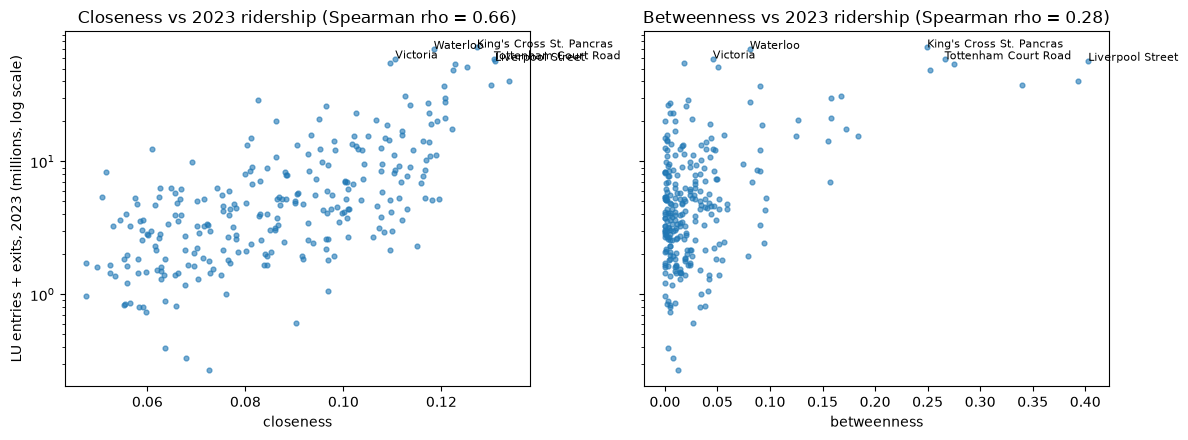

In [4]:
riders = panel[2023].dropna()
riders = riders[riders.index.isin(cent24.index)]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, m in zip(axs, ['closeness', 'betweenness']):
    ax.scatter(cent24.loc[riders.index, m], riders / 1e6, s=12, alpha=0.6)
    for s in riders.nlargest(5).index:
        ax.annotate(s, (cent24.loc[s, m], riders[s] / 1e6), fontsize=8)
    rho = corr.query("measure == @m and comparison.str.startswith('2024')").spearman_rho.iloc[0]
    ax.set_title(f'{m.capitalize()} vs 2023 ridership (Spearman rho = {rho:.2f})')
    ax.set_xlabel(m)
    ax.set_yscale('log')
axs[0].set_ylabel('LU entries + exits, 2023 (millions, log scale)')
plt.tight_layout(); plt.show()

**Reading.** Closeness (how few stops a station is from everywhere else) is the best predictor of how busy a station
is (rho about 0.7), followed by Katz and degree. Betweenness, the measure the dissertation leaned on most, is a much
weaker predictor (rho about 0.3), and PageRank weaker still. Being *on many shortest paths* says more about
interchange load inside the network than about how many people start or end journeys at a station.

## 2. The Elizabeth line's effect on station traffic (difference-in-differences)

**Treated stations.** The four brand-new central Elizabeth line stations whose Elizabeth line passengers pass through the
LU ticket gates (TfL marks them `---see LU---`): **Bond Street, Tottenham Court Road, Farringdon, Whitechapel**.

**Reported separately.**
* *Paddington, Liverpool Street*: the predecessor TfL Rail service was counted separately until 2022, so part of their
  jump is a change in what the LU gate count covers.
* *Canary Wharf*: the Elizabeth line station is a separate building, counted separately, so the LU count there
  measures passengers *switching away* from the Underground.

**Excluded from the control group.** The stations above, plus Stratford and Ealing Broadway (already served by TfL Rail before 2022).

**Control group.** Other LU stations within 4 km of the treated stations' centre, so that both groups shared the same
slow post-COVID recovery of central London. A version with every other LU station is reported for comparison.

**Estimate.** For each year, the change in log entries + exits since 2019 for treated stations minus the same change for
control stations. Converted to a percentage, it is how much more the treated stations grew than comparable stations.

In [5]:
treated = ['Bond Street', 'Tottenham Court Road', 'Farringdon', 'Whitechapel']
reported = ['Paddington', 'Liverpool Street', 'Canary Wharf']
excluded = set(treated + reported + ['Stratford', 'Ealing Broadway'])

pos = T.positions_2024()
def km(a, b):
    (lo1, la1), (lo2, la2) = np.radians(a), np.radians(b)
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))

centre = tuple(np.mean([pos[s] for s in treated], axis=0))
dist_km = pd.Series({s: km(pos[s], centre) for s in balanced.index})
control_all = [s for s in balanced.index if s not in excluded]
control_central = [s for s in control_all if dist_km[s] <= 4]
print(f"treated: {treated}")
print(f"central control: {len(control_central)} stations within 4 km; all-LU control: {len(control_all)} stations")

treated: ['Bond Street', 'Tottenham Court Road', 'Farringdon', 'Whitechapel']
central control: 56 stations within 4 km; all-LU control: 251 stations


In [6]:
log_counts = np.log(balanced)
change = log_counts.sub(log_counts[2019], axis=0)   # log change since 2019, per station and year

def did(group, control, year):
    return change.loc[group, year].mean() - change.loc[control, year].mean()

event = pd.DataFrame({
    'central control (%)': {y: 100 * (np.exp(did(treated, control_central, y)) - 1) for y in T.ANNUAL_YEARS},
    'all-LU control (%)': {y: 100 * (np.exp(did(treated, control_all, y)) - 1) for y in T.ANNUAL_YEARS},
}).round(1)
event.index.name = 'year'
event.to_csv(T.RESULTS / 'elizabeth_line_did_by_year.csv')
event

,central control (%),all-LU control (%)
year,,
2017,-7.9,-7.3
2018,-0.9,-0.8
2019,0.0,0.0
2020,2.5,-39.4
2021,5.7,-7.3
2022,56.4,47.0
2023,83.8,69.6
2024,84.0,70.9
2025,94.2,80.5


**Pre-trend check.** In 2018 the treated stations moved with the control group (about −1%), and during the COVID years
2020-2021 they stayed close to it against the central control. 2017 is lower (about −8%), but 2017 counts are modelled
(`Relate`) rather than gate counts, and Farringdon's 2018 jump coincides with the Thameslink upgrade. The effect starts
in 2022, the year the line opened (May 2022, so a part year), and is stable from 2023.

In [7]:
# Inference: with only four treated stations, standard errors are unreliable, so use a placebo (permutation) test.
# Draw 4 random control stations, pretend they were treated, and repeat 10,000 times.
year = 2023
observed = did(treated, control_central, year)
placebo = np.array([did(list(rng.choice(control_central, 4, replace=False)), control_central, year)
                    for _ in range(10_000)])
p_value = (np.sum(placebo >= observed) + 1) / (len(placebo) + 1)

# Regression form of the same estimate (two periods, station and year fixed effects), robust SEs
long = (log_counts.loc[treated + control_central, [2019, year]].stack().rename('log_ee').reset_index())
long['treated'] = long['station'].isin(treated).astype(int)
long['post'] = (long['year'] == year).astype(int)
model = smf.ols('log_ee ~ treated:post + C(station) + C(year)', data=long).fit(cov_type='HC1')
beta, (lo, hi) = model.params['treated:post'], model.conf_int().loc['treated:post']

# Extra entries + exits in 2023 at the four stations versus the counterfactual (2019 x control growth)
control_growth = np.exp(change.loc[control_central, year].mean())
counterfactual = balanced.loc[treated, 2019] * control_growth
extra = balanced.loc[treated, year] - counterfactual

summary = pd.Series({
    'effect 2019->2023, % (central control)': round(100 * (np.exp(observed) - 1), 1),
    'regression 95% CI, %': f"{100 * (np.exp(lo) - 1):.0f} to {100 * (np.exp(hi) - 1):.0f}",
    'placebo p-value': round(p_value, 4),
    'largest placebo effect, %': round(100 * (np.exp(placebo.max()) - 1), 1),
    'extra entries+exits 2023 at the 4 stations (millions)': round(extra.sum() / 1e6, 1),
})
summary.to_csv(T.RESULTS / 'elizabeth_line_did_summary.csv', header=['value'])
summary.to_frame('value')

,value
"effect 2019->2023, % (central control)",83.8
"regression 95% CI, %",56 to 117
placebo p-value,0.0001
"largest placebo effect, %",26.6
extra entries+exits 2023 at the 4 stations (millions),69.7


In [8]:
# Station by station (2019 -> 2023, relative to the central control group)
stations = treated + reported
per_station = pd.DataFrame({
    'group': ['treated'] * len(treated) + ['reported separately'] * len(reported),
    '2019 (M)': balanced.loc[stations, 2019] / 1e6,
    '2023 (M)': balanced.loc[stations, 2023] / 1e6,
    '2025 (M)': balanced.loc[stations, 2025] / 1e6,
    'effect vs control 2019->2023 (%)': [100 * (np.exp(change.loc[s, 2023] - change.loc[control_central, 2023].mean()) - 1)
                                          for s in stations],
}, index=stations).round(1)
per_station.to_csv(T.RESULTS / 'elizabeth_line_station_effects.csv')
per_station

,group,2019 (M),2023 (M),2025 (M),effect vs control 2019->2023 (%)
Bond Street,treated,37.5,37.4,42.3,40.9
Tottenham Court Road,treated,42.0,58.7,60.8,97.4
Farringdon,treated,25.9,40.1,42.0,118.1
Whitechapel,treated,13.1,17.5,17.9,88.2
Paddington,reported separately,48.6,48.5,58.0,40.9
Liverpool Street,reported separately,67.2,57.2,60.1,20.2
Canary Wharf,reported separately,47.7,30.9,32.6,-8.7


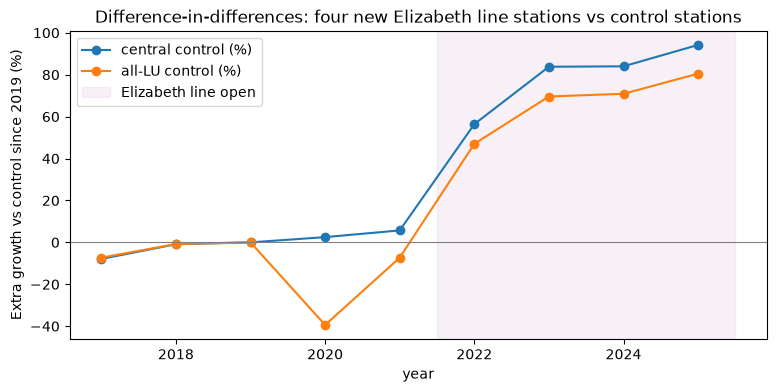

In [9]:
ax = event.plot(marker='o', figsize=(9, 4))
ax.axhline(0, color='grey', linewidth=0.8)
ax.axvspan(2021.5, 2025.5, color='purple', alpha=0.06, label='Elizabeth line open')
ax.set_ylabel('Extra growth vs control since 2019 (%)')
ax.set_title('Difference-in-differences: four new Elizabeth line stations vs control stations')
ax.legend(); plt.show()

**Reading.** Between 2019 and 2023 the four new Elizabeth line stations grew about **84% more** than comparable
central-London stations. No placebo group of four control stations came close, and the effect held steady through
2024-2025 (card-tap counts). Farringdon, the Elizabeth line/Thameslink interchange, roughly doubled relative to the
control group. Canary Wharf's Underground station lost ground (−9%) as passengers moved to the separate
Elizabeth line station next door.

This measures *traffic through those stations*, which includes passengers who switched from nearby stations. It is
not an estimate of new journeys created across the whole network.

## 3. Network resilience

**Network efficiency** is the average of 1 / (number of stops) over all pairs of stations: 1 means every station is one
stop from every other, and 0 means no connection. It falls as stations close, and it stays meaningful when the network
splits into pieces.

* **Single-station closure:** close one station at a time and measure the % of efficiency lost.
* **Targeted attack:** repeatedly close the station with the highest betweenness (recomputed after each closure).
* **Random failure:** close stations at random (mean of 200 runs).

In [10]:
networks = {'2014': G14, '2024': G24, '2024 without Elizabeth line': G24_no_el}

def efficiency(G):
    if G.number_of_nodes() < 2:
        return 0.0
    D = shortest_path(nx.to_scipy_sparse_array(G, format='csr'), unweighted=True, directed=False)
    n = D.shape[0]
    finite = D[np.isfinite(D) & (D > 0)]
    return (1.0 / finite).sum() / (n * (n - 1))

base = {name: efficiency(G) for name, G in networks.items()}
pd.Series(base, name='efficiency').round(4).to_frame()

,efficiency
2014,0.1022
2024,0.1073
2024 without Elizabeth line,0.1003


In [11]:
# Single-station closures
single = {}
for name, G in networks.items():
    loss = {}
    for v in G.nodes:
        H = G.copy(); H.remove_node(v)
        loss[v] = 100 * (1 - efficiency(H) / base[name])
    single[name] = pd.Series(loss)
single = pd.DataFrame(single)
single.round(3).to_csv(T.RESULTS / 'resilience_single_station.csv', index_label='station')

top = {name: [f"{s} ({v:.1f}%)" for s, v in single[name].nlargest(8).items()] for name in networks}
pd.DataFrame(top, index=range(1, 9))

,2014,2024,2024 without Elizabeth line
1,Euston (9.8%),Stratford (12.3%),Euston (9.4%)
2,Stratford (9.0%),Euston (8.4%),Stratford (8.6%)
3,Camden Town (7.7%),Camden Town (6.8%),Camden Town (7.3%)
4,Leyton (6.6%),Leyton (6.7%),Leyton (6.4%)
5,Leytonstone (6.2%),Leytonstone (6.1%),Leytonstone (5.9%)
6,Canning Town (6.1%),Canary Wharf (5.4%),Canning Town (5.8%)
7,Willesden Junction (5.8%),Liverpool Street (5.1%),Willesden Junction (5.4%)
8,Surrey Quays (5.1%),Paddington (4.7%),Finsbury Park (4.9%)


In [12]:
# Cumulative failures
MAX_REMOVED, RANDOM_RUNS = 40, 200

def targeted_curve(G):
    H, out = G.copy(), [1.0]
    E0 = efficiency(G)
    for _ in range(MAX_REMOVED):
        bc = nx.betweenness_centrality(H)
        H.remove_node(max(bc, key=lambda k: (bc[k], k)))
        out.append(efficiency(H) / E0)
    return out

def random_curve(G):
    E0, nodes = efficiency(G), list(G.nodes)
    runs = []
    for _ in range(RANDOM_RUNS):
        H = G.copy(); order = rng.permutation(nodes)[:MAX_REMOVED]
        curve = [1.0]
        for v in order:
            H.remove_node(v); curve.append(efficiency(H) / E0)
        runs.append(curve)
    return np.mean(runs, axis=0)

curves = pd.DataFrame({'stations_removed': range(MAX_REMOVED + 1)})
for name, G in networks.items():
    curves[f'{name} | targeted'] = targeted_curve(G)
    curves[f'{name} | random'] = random_curve(G)
curves.round(4).to_csv(T.RESULTS / 'resilience_curves.csv', index=False)
curves.set_index('stations_removed').loc[[5, 10, 20, 40]].mul(100).round(1)

,2014 | targeted,2014 | random,2024 | targeted,2024 | random,2024 without Elizabeth line | targeted,2024 without Elizabeth line | random
stations_removed,,,,,,
5,59.7,95.2,77.5,96.0,58.9,95.4
10,32.9,90.4,48.7,91.5,34.3,90.7
20,16.6,80.6,17.0,83.4,16.8,81.2
40,9.3,63.3,8.6,67.5,9.4,64.4


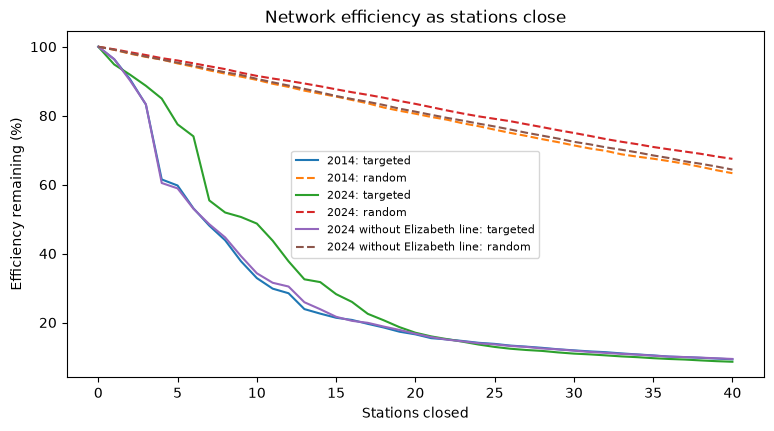

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in networks:
    ax.plot(curves.stations_removed, 100 * curves[f'{name} | targeted'], label=f'{name}: targeted')
    ax.plot(curves.stations_removed, 100 * curves[f'{name} | random'], linestyle='--', label=f'{name}: random')
ax.set_xlabel('Stations closed'); ax.set_ylabel('Efficiency remaining (%)')
ax.set_title('Network efficiency as stations close'); ax.legend(fontsize=8); plt.show()

**Reading.**

* **Random closures degrade the network gradually.** Ten random closures cost about 9% of efficiency and forty cost about
  a third, in every version of the network.
* **Targeted closures of the most central stations are far more damaging, and this is where the Elizabeth line helps.**
  After the 10 most central stations close, the 2024 network keeps **49%** of its efficiency, against 33% in 2014 and 34%
  for 2024 without the Elizabeth line. The line adds a second east-west trunk, so traffic has another way across London.
  The advantage disappears by about 20 closures, when every version is badly fragmented.
* **The flip side is concentration at Stratford.** It is the single most damaging closure in 2024 (12.3% of efficiency
  lost, up from 9.0% in 2014), and Canary Wharf enters the top six. Leyton and Leytonstone rank highly in every year
  because the Central line's Epping and Hainault branches depend on them.